# 01 · MODIS reproduction: baselines and history features

**Purpose.** An intern's review of this module's land-use forecasting raised the Figure of Merit (FoM) from **20.0% to 28.06%** on the MODIS land-cover series. 
This notebook reruns the methodology improvement code and checks every figure before carrying it over to the deployed ESRI configuration.

This notebook covers the following steps:

| Section | What it tests | Intern's headline |
|---|---|---|
| 1 | The input maps and how much of their "change" is label flicker | 33–38% of changes revert |
| 2 | Original-style baselines (the method the platform uses) | 20.02–20.91% |
| 3 | Adding land-cover history features | 22.89–24.03% |
| 4 | Change-focused models and decision thresholds | 26.24% |
| 5 | Longer history, pooled periods | 26.93% (control) |

| 

> **Not comparable with the deployed module's 13.80%.** The intern worked on MODIS 500 m maps at 5-year steps and their models predict *how much* change happens as well as *where*. 
> The deployed module uses ESRI 10 m annual maps and is given the observed amount of change. Different product, interval and task.

**Figure of Merit** (Pontius et al., 2008) = correctly predicted changes ÷ (observed changes ∪ predicted changes). A change counts as correct only if **both the place and the new class** are right. Overall accuracy is shown too, but "no change anywhere" already scores 92.41% on these maps, so FoM is the measure that matters.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H          
import numpy as np, pandas as pd, matplotlib.pyplot as plt

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})

# Switch any of these to True to recompute that step instead of loading the saved run.
RERUN = {"baselines": False,      # ~2 min
         "history": False,        # ~6 min
         "advanced": False,       # ~35 min
         "longer_history": False} # ~13 min
H.RERUN_LABEL = H.RERUN_PY310    # how this notebook's rerun columns are labelled

print("Intern code: 1_intern_improvement/local_landuse/ (unchanged; one file location, see PROVENANCE.md)")
H.environment()

Intern code: local_landuse/ (unchanged)


,package,version
0,python,3.10.0
1,numpy,2.2.6
2,scikit-learn,1.7.2
3,xgboost,3.2.0
4,scipy,1.15.3
5,rasterio,1.4.4
6,pandas,2.3.3


## 1 · The input maps

Six MODIS MCD12Q1 land-cover maps (IGBP legend, ~500 m) and one terrain stack.

In [2]:
rows = []
for year in (2001, 2005, 2010, 2015, 2020, 2024):
    name = f"Guinea_LandCover_{year}.tif"
    arr, prof = H.read_map(name)
    rows.append((name, f"{prof['width']}×{prof['height']}", f"{prof['transform'].a:.5f}°",
                 int(((arr != 0) & (arr != 255)).sum())))
_, terrain = H.read_map("Guinea_SRTM_DEM_Slope_Aspect.tif")
rows.append(("Guinea_SRTM_DEM_Slope_Aspect.tif", f"{terrain['width']}×{terrain['height']}",
             f"{terrain['transform'].a:.5f}°", None))
H.show(pd.DataFrame(rows, columns=["File", "Grid (cols×rows)", "Cell size", "Labelled pixels"]), 0)

File,Grid (cols×rows),Cell size,Labelled pixels
Guinea_LandCover_2001.tif,1656×1222,0.00449°,1002010
Guinea_LandCover_2005.tif,1656×1222,0.00449°,1002010
Guinea_LandCover_2010.tif,1656×1222,0.00449°,1002010
Guinea_LandCover_2015.tif,1656×1222,0.00449°,1002010
Guinea_LandCover_2020.tif,1656×1222,0.00449°,1002010
Guinea_LandCover_2024.tif,1656×1222,0.00449°,1002010
Guinea_SRTM_DEM_Slope_Aspect.tif,1656×1222,0.00449°,


**Land-cover classes, 2015.** Savanna dominates. The three savanna-type classes
(woody savanna, savanna, grassland) cover about 91% of the labelled area, and
the intern found that most observed change, and most false alarms, happen among
those three.

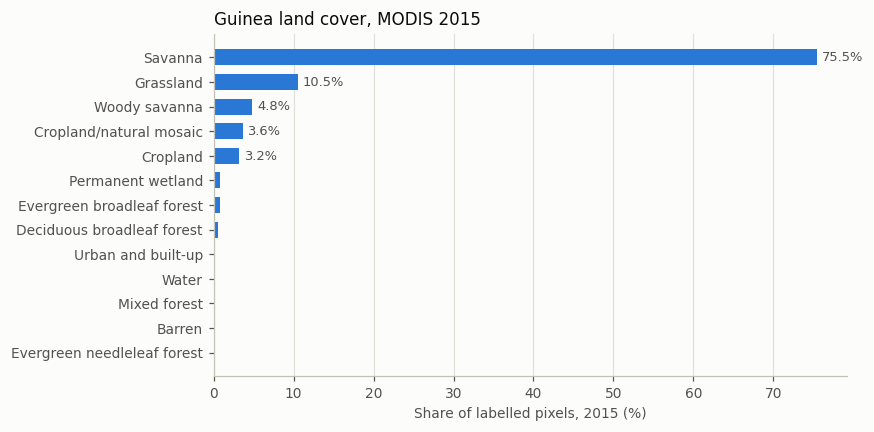

Code,Class,Pixels,Share %
9,Savanna,756257,75.47
10,Grassland,105590,10.54
8,Woody savanna,48161,4.81
14,Cropland/natural mosaic,36258,3.62
12,Cropland,31643,3.16
11,Permanent wetland,7959,0.79
2,Evergreen broadleaf forest,7694,0.77
4,Deciduous broadleaf forest,5233,0.52
13,Urban and built-up,1522,0.15
17,Water,1027,0.10


In [3]:
lc15, _ = H.read_map("Guinea_LandCover_2015.tif")
codes, counts = np.unique(lc15[(lc15 != 0) & (lc15 != 255)], return_counts=True)
classes = pd.DataFrame({"Code": codes, "Class": [H.IGBP.get(int(c), "?") for c in codes],
                        "Pixels": counts})
classes["Share %"] = 100 * classes["Pixels"] / classes["Pixels"].sum()
classes = classes.sort_values("Pixels", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
data = classes.iloc[::-1]
ax.barh(data["Class"], data["Share %"], color=H.SERIES[0], height=0.65)
for y, v in enumerate(data["Share %"]):
    if v >= 1:
        ax.text(v + 0.6, y, f"{v:.1f}%", va="center", color=H.INK_2, fontsize=8.5)
H.style_axes(ax)
ax.set_xlabel("Share of labelled pixels, 2015 (%)", color=H.INK_2)
ax.set_title("Guinea land cover, MODIS 2015", loc="left", color=H.INK, fontsize=11)
plt.tight_layout(); plt.show()
H.show(classes)

**The evaluation set.** Every score in the intern's write-ups uses the same
**992,833 pixels**, of which **75,365 (7.59%) changed class** between 2015 and 2020.
Matching both counts exactly confirms the inputs and the masking are the same.

In [4]:
mask = H.read_output_raster("controlled_2010_2015_2020/temporal_holdout/evaluation_mask.tif").astype(bool)
lc20, _ = H.read_map("Guinea_LandCover_2020.tif")
changed = (lc20 != lc15) & mask
print(f"Evaluation pixels: {mask.sum():,}   (intern: 992,833)")
print(f"Observed changes:  {changed.sum():,} = {100 * changed.sum() / mask.sum():.2f}%   (intern: 75,365 = 7.59%)")

pairs = pd.DataFrame({"from": lc15[changed], "to": lc20[changed]}).value_counts().head(8).reset_index(name="Pixels")
pairs["Transition"] = [f"{H.IGBP[a]} → {H.IGBP[b]}" for a, b in zip(pairs["from"], pairs["to"])]
pairs["Share of change %"] = 100 * pairs["Pixels"] / changed.sum()
H.show(pairs[["Transition", "Pixels", "Share of change %"]])

Evaluation pixels: 992,833   (intern: 992,833)
Observed changes:  75,365 = 7.59%   (intern: 75,365 = 7.59%)


Transition,Pixels,Share of change %
Savanna → Grassland,18009,23.90
Grassland → Savanna,8668,11.50
Savanna → Woody savanna,7788,10.33
Cropland/natural mosaic → Savanna,7097,9.42
Savanna → Cropland/natural mosaic,6191,8.21
Cropland → Grassland,4631,6.14
Savanna → Cropland,3953,5.25
Grassland → Cropland,3604,4.78


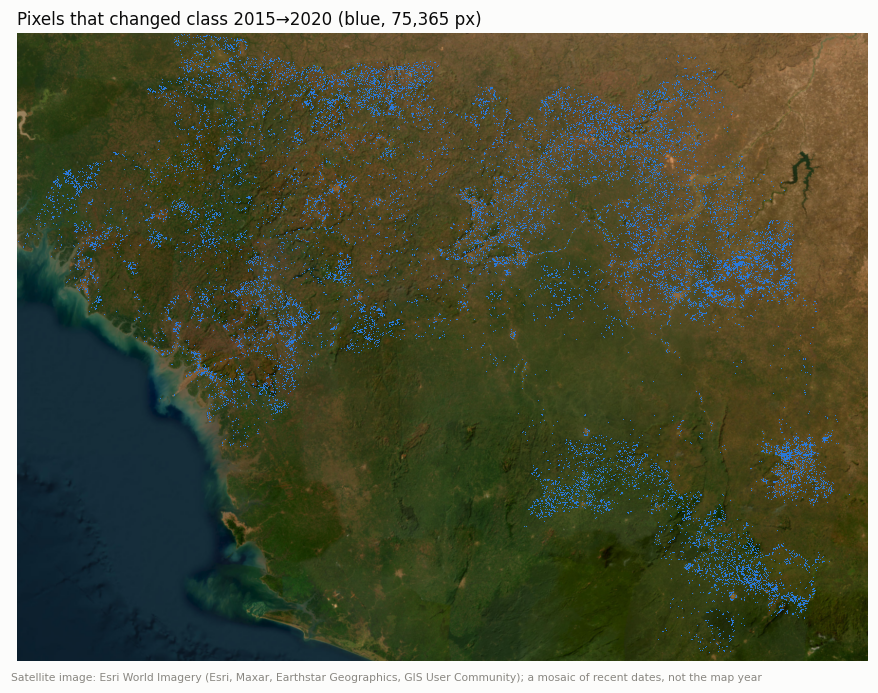

In [5]:
view = np.where(mask, np.where(changed, 2, 1), 0)
fig, ax = plt.subplots(figsize=(8, 6.2))
from matplotlib.colors import ListedColormap
H.plot_satellite(ax, H.read_map("Guinea_LandCover_2015.tif")[1])
ax.imshow(np.ma.masked_less_equal(view, 1), cmap=ListedColormap(["#ffffff", H.NEUTRAL_FILL, H.SERIES[0]]), vmin=0, vmax=2,
          interpolation="nearest")
ax.set_axis_off()
ax.set_title(f"Pixels that changed class 2015→2020 (blue, {changed.sum():,} px)",
             loc="left", color=H.INK, fontsize=11)
H.satellite_credit(fig)
plt.tight_layout(); plt.show()

### How much of the "change" is label flicker?

- A pixel that changes in one interval and **returns to its original class** in the next is more likely to be classification noise.
- Any change that is noise cannot be predicted, so it caps the achievable FoM. 
- The MODIS user guide warns against reading annual class differences directly as change.

This reads 2020 and 2024, so it is a diagnostic only.

In [6]:
maps = {y: H.read_map(f"Guinea_LandCover_{y}.tif")[0] for y in (2001, 2005, 2010, 2015, 2020, 2024)}
valid = lambda a: (a != 0) & (a != 255)
rows = []
for a, b, c in [(2001, 2005, 2010), (2005, 2010, 2015), (2010, 2015, 2020), (2015, 2020, 2024)]:
    ok = valid(maps[a]) & valid(maps[b]) & valid(maps[c])
    first = ok & (maps[a] != maps[b])
    back = first & (maps[c] == maps[a])
    rows.append((f"{a}→{b}", f"{b}→{c}", int(first.sum()), int(back.sum()), 100 * back.sum() / first.sum()))
reversion = pd.DataFrame(rows, columns=["Changed in", "Returned in", "Changed px", "Returned px", "Returned %"])
H.show(reversion, 1)

Changed in,Returned in,Changed px,Returned px,Returned %
2001→2005,2005→2010,158133,24222,15.3
2005→2010,2010→2015,75448,28586,37.9
2010→2015,2015→2020,74017,24420,33.0
2015→2020,2020→2024,76029,21992,28.9


All three later rows match the intern's figures exactly: 37.9% (2005→2010→2015), 33.0% (2010→2015→2020) and 28.9% (2015→2020→2024).

**Reading this:** between a sixth and two fifths of the change in each interval is undone in the next one. That is the same order as the hits any model scores, which is why the intern concluded the remaining gap to 40% is mostly in the labels, not the models.

---

## 2 · The platform's method baseline

Three ways of predicting the 2020 map from 2010→2015 history. All use terrain (elevation, slope, aspect), the starting class and the 3×3 neighbourhood class mix as predictors, and allocate the historical amount of each transition:

* **Original-style transition RF**: one binary Random Forest per transition
  (A→B against A staying A), with balanced samples per transition. This is the
  structure the deployed `landuse_tool` uses.
* **Binary RF, shared samples**: the same, but every forest sees the identical
  100,000 pixels and the identical 100×100-pixel spatial blocks.
* **Multiclass RF, shared samples**: *one* forest predicting the next class
  directly, on those same pixels. Its probabilities feed the same allocator.

Fit on 2010→2015 → forecast 2015→2020. The 2020 map is loaded only after the
forecast is saved.

In [7]:
controlled = H.ensure_run("local_landuse", "controlled_2010_2015_2020",
                          ["--experiment", "controlled", "--no-plot"], RERUN["baselines"])
legacy = H.ensure_run("local_landuse", "local_comparison_2010_2015_2020",
                      ["--experiment", "direct", "--sampling", "legacy_balanced", "--no-plot"], RERUN["baselines"])

t = H.read_csv(controlled / "temporal_holdout/comparison.csv")
s = H.read_csv(controlled / "spatial_holdout/comparison.csv")
l = H.read_csv(legacy / "comparison.csv")
f, a = "figure_of_merit_pct", "overall_accuracy"
baselines = H.compare([
    ("Original-style transition RF", 20.02, H.row(l, "model", "transition_rf_allocation", f),
     90.28, 100 * H.row(l, "model", "transition_rf_allocation", a)),
    ("Binary RF, shared samples", 20.29, H.row(t, "model", "binary_rf_allocation", f),
     90.60, 100 * H.row(t, "model", "binary_rf_allocation", a)),
    ("Multiclass RF, shared samples", 20.91, H.row(t, "model", "multiclass_rf_allocation", f),
     90.72, 100 * H.row(t, "model", "multiclass_rf_allocation", a)),
    ("  ↳ binary, spatial hold-out 2010→2015", 21.72, H.row(s, "model", "binary_rf_allocation", f), None, None),
    ("  ↳ multiclass, spatial hold-out 2010→2015", 22.35, H.row(s, "model", "multiclass_rf_allocation", f), None, None),
])
H.show(baselines)

Using saved: outputs/controlled_2010_2015_2020
Using saved: outputs/local_comparison_2010_2015_2020


Configuration,Intern FoM %,"Rerun (Python 3.10, xgboost 3.2) FoM %",Δ FoM (pts),Intern accuracy %,"Rerun (Python 3.10, xgboost 3.2) accuracy %",Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
Original-style transition RF,20.02,20.00,-0.02,90.28,90.28,0.40,yes
"Binary RF, shared samples",20.29,20.29,0.00,90.60,90.60,0.40,yes
"Multiclass RF, shared samples",20.91,20.82,-0.09,90.72,90.71,0.40,yes
"↳ binary, spatial hold-out 2010→2015",21.72,21.72,0.00,,,0.40,yes
"↳ multiclass, spatial hold-out 2010→2015",22.35,22.36,0.01,,,0.40,yes


**Result: reproduces.** The binary-RF rows match to the hundredth. The
multiclass rows differ by under 0.1 point, which is consistent with
scikit-learn 1.7 here against 1.9 for the intern (Random Forest tree building
changed between versions). A single multiclass forest beats one forest per
transition by about 0.5 point on identical data. That is small, but it is the
first hint that the per-transition structure is not the strongest choice.

---

## 3 · Adding land-cover history features

Tell the model **what each pixel was
before**, not only what it is now. New predictors (47, then 101 in total):

* previous class, whether the pixel changed in the last interval, the interval length;
* the share of recently changed pixels around it, and the distance to the nearest recent change;
* class mix in 7×7 and 15×15 windows and how that mix has been trending.

**Selection:** candidates are fitted on 2005→2010, scored on
2010→2015 in held-out spatial blocks, and the winner plus its allocation settings
are written to `frozen_selection.json` *before* the 2020 map is read. Then each
candidate is refitted on 2010→2015 and forecasts 2015→2020.

In [8]:
history = H.ensure_run("local_landuse.improvements", "improvements_20260909", ["--no-plot"], RERUN["history"])
fc = H.read_csv(history / "final_comparison.csv")
g = lambda name, col=f: H.row(fc, "name", name, col) * (100 if col == a else 1)
history_rows = H.compare([
    ("Multiclass RF baseline (29 features)", 20.91, g("rf_baseline"), 90.72, g("rf_baseline", a)),
    ("RF + history (selected on validation)", 22.89, g("rf_history"), 91.10, g("rf_history", a)),
    ("RF + history + larger neighbourhoods", 23.61, g("rf_history_multiscale"), 91.23, g("rf_history_multiscale", a)),
    ("Regularized RF, all features", 23.41, g("rf_regularized"), 91.19, g("rf_regularized", a)),
    ("Flexible RF, all features", 22.38, g("rf_flexible"), 90.99, g("rf_flexible", a)),
    ("Shallow XGBoost, all features", 24.03, g("xgb_shallow"), 91.31, g("xgb_shallow", a)),
    ("Deeper XGBoost, all features", 23.70, g("xgb_deeper"), 91.25, g("xgb_deeper", a)),
    ("Selected RF + tuned allocation", 24.16, g("selected_with_allocation_change"), 90.36,
     g("selected_with_allocation_change", a)),
])
import json
frozen = json.loads((history / "frozen_selection.json").read_text())
print(f"Frozen before reading 2020: model = {frozen['model']['name']} "
      f"(validation FoM {frozen['validation_score']:.2f}%, intern 20.58%); "
      f"allocation = demand ×{frozen['allocation']['demand_factor']}, "
      f"min. probability {frozen['allocation']['minimum_probability']} "
      f"(validation FoM {frozen['allocation_validation_score']:.2f}%, intern 22.05%)")
H.show(history_rows)

Using saved: outputs/improvements_20260909
Frozen before reading 2020: model = rf_history (validation FoM 20.67%, intern 20.58%); allocation = demand ×1.25, min. probability 0.1 (validation FoM 22.06%, intern 22.05%)


Configuration,Intern FoM %,"Rerun (Python 3.10, xgboost 3.2) FoM %",Δ FoM (pts),Intern accuracy %,"Rerun (Python 3.10, xgboost 3.2) accuracy %",Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
Multiclass RF baseline (29 features),20.91,20.82,-0.09,90.72,90.71,0.40,yes
RF + history (selected on validation),22.89,22.93,0.04,91.10,91.11,0.40,yes
RF + history + larger neighbourhoods,23.61,23.41,-0.20,91.23,91.20,0.40,yes
"Regularized RF, all features",23.41,23.39,-0.02,91.19,91.19,0.40,yes
"Flexible RF, all features",22.38,22.28,-0.10,90.99,90.98,0.40,yes
"Shallow XGBoost, all features",24.03,24.01,-0.02,91.31,91.32,0.40,yes
"Deeper XGBoost, all features",23.70,23.78,0.08,91.25,91.27,0.40,yes
Selected RF + tuned allocation,24.16,24.14,-0.02,90.36,90.35,0.40,yes


**Result: reproduces**, and validation freezes the same choice as the intern's.
History features add about **2 points** over the same-sample baseline, and
shallow XGBoost on all features adds about **3**. This is the idea most worth
carrying over to the ESRI module: the annual ESRI series has six previous years
to draw history from, where MODIS had two or three.

---

## 4 · Change-focused models and decision thresholds

The previous models allocate a fixed, historical amount of each transition. This
round lets the model **decide how much changes** by learning decision
thresholds on validation, and tries model structures aimed at change:

* **two-stage**: first "does this pixel change?", then "into what?";
* **relative actions**: stay / return to the previous class / move elsewhere;
* changed-pixel weighting, patch-geometry features, more training pixels, a small ensemble.

Same selection protocol as section 3: fit 2005→2010, select on 2010→2015, freeze,
refit, forecast. Each candidate is also scored with the common **fixed demand**
for comparison.

In [9]:
advanced = H.ensure_run("local_landuse.advanced", "advanced_20260909", [], RERUN["advanced"])
actions = H.ensure_run("local_landuse.actions", "actions_20260909", [], RERUN["advanced"])
summary_dir = H.ensure_run("local_landuse.advanced_summary", "fom40_summary_20260909",
                           ["--runs", f"outputs/{advanced.name}", f"outputs/{actions.name}"], RERUN["advanced"])
adv = H.read_csv(summary_dir / "comparison.csv")
v = lambda name, col=f: H.row(adv, "name", name, col) * (100 if col == a else 1)
advanced_rows = H.compare([
    ("History RF + selected change thresholds", 25.60, v("rf_history_control"), 89.63, v("rf_history_control", a)),
    ("Two-stage RF (selected on validation)", 26.24, v("two_stage_rf"), 88.92, v("two_stage_rf", a)),
    ("  ↳ two-stage RF, fixed demand", 23.73, v("two_stage_rf", "fixed_demand_fom"), None, None),
    ("  ↳ ensemble, fixed demand", 24.24, v("ensemble", "fixed_demand_fom"), None, None),
    ("Weighted XGBoost + patch features (best final row)", 26.49, v("xgb_geometry_weight4"), 89.27,
     v("xgb_geometry_weight4", a), H.TOL_XGB_THRESHOLD),
])
# The same module rerun in the intern's pinned environment (see the next cell)
INTERN_ENV = H.OUTPUTS / "advanced_intern_env_py314"
ie = H.read_csv(INTERN_ENV / "final_comparison.csv")
w = lambda name: H.row(ie, "name", name, f)
advanced_rows.insert(3, f"{H.RERUN_PY314} FoM %", [w("rf_history_control"), w("two_stage_rf"), w("two_stage_rf_fixed_demand"),
                                                     w("ensemble_fixed_demand"), w("xgb_geometry_weight4")])
print(f"Selected on validation, {H.RERUN_PY310}:", adv.loc[adv["selected"].astype(str) == "True", "name"].tolist(),
      f"| {H.RERUN_PY314}:", json.loads((INTERN_ENV / "frozen_selection.json").read_text())["selected_model"])
H.show(advanced_rows)

Using saved: outputs/advanced_20260909
Using saved: outputs/actions_20260909
Using saved: outputs/fom40_summary_20260909
Selected on validation, Rerun (Python 3.10, xgboost 3.2): ['two_stage_rf'] | Rerun (Python 3.14, xgboost 3.4.1): two_stage_xgb


Configuration,Intern FoM %,"Rerun (Python 3.10, xgboost 3.2) FoM %","Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts),Intern accuracy %,"Rerun (Python 3.10, xgboost 3.2) accuracy %",Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
History RF + selected change thresholds,25.60,25.60,25.60,-0.00,89.63,89.73,0.40,yes
Two-stage RF (selected on validation),26.24,25.88,26.21,-0.36,88.92,88.97,0.40,yes
"↳ two-stage RF, fixed demand",23.73,23.64,23.78,-0.09,,,0.40,yes
"↳ ensemble, fixed demand",24.24,24.29,24.14,0.05,,,0.40,yes
Weighted XGBoost + patch features (best final row),26.49,24.84,25.69,-1.65,89.27,89.82,0.85,NO


**Is it the package versions?** The same module was rerun with the intern's exact versions (`local_landuse/requirements-intern.txt`: Python 3.14, xgboost 3.4.1, scikit-learn 1.9.0) in a separate environment (README), into `outputs/advanced_intern_env_py314`. Comparing every candidate between the two runs shows how far versions alone move each kind of row:

In [10]:
ours_all = H.read_csv(advanced / "final_comparison.csv").set_index("name")[f]
theirs_all = ie.set_index("name")[f]
def kind(name):
    if name.endswith("_fixed_demand"):
        return "Fixed demand (RF and XGBoost)"
    return "RF, tuned thresholds" if name.startswith(("rf_", "two_stage_rf")) else "XGBoost, tuned thresholds"
env = pd.DataFrame({"Rerun (Python 3.10, xgboost 3.2) FoM %": ours_all, "Rerun (Python 3.14, xgboost 3.4.1) FoM %": theirs_all})
env = env.drop(index="no_change")
env["|Δ| (pts)"] = (env.iloc[:, 0] - env.iloc[:, 1]).abs()
env["Kind"] = [kind(n) for n in env.index]
spread = env.groupby("Kind")["|Δ| (pts)"].agg(["max", "count"]).rename(columns={"max": "Largest version-only change (pts)", "count": "Rows"})
display(H.show(spread.reset_index(), 2))
print("Largest differences, candidate by candidate:")
display(H.show(env.reset_index().rename(columns={"name": "Candidate"}).sort_values("|Δ| (pts)", ascending=False).head(8), 2))
print(f"Tolerances used in every comparison table: {H.TOL} points, and {H.TOL_XGB_THRESHOLD} for XGBoost rows "
      "with tuned decision thresholds (nb_helpers.TOL, TOL_XGB_THRESHOLD).")

Kind,Largest version-only change (pts),Rows
Fixed demand (RF and XGBoost),0.32,12
"RF, tuned thresholds",0.33,2
"XGBoost, tuned thresholds",0.85,10


Largest differences, candidate by candidate:


Candidate,"Rerun (Python 3.10, xgboost 3.2) FoM %","Rerun (Python 3.14, xgboost 3.4.1) FoM %",|Δ| (pts),Kind
xgb_geometry_weight4,24.84,25.69,0.85,"XGBoost, tuned thresholds"
ensemble,26.34,25.84,0.50,"XGBoost, tuned thresholds"
xgb_geometry_deep,24.48,24.86,0.38,"XGBoost, tuned thresholds"
two_stage_rf,25.88,26.21,0.33,"RF, tuned thresholds"
xgb_geometry_deep_fixed_demand,22.57,22.89,0.32,Fixed demand (RF and XGBoost)
xgb_more_samples,25.77,26.08,0.31,"XGBoost, tuned thresholds"
xgb_geometry,25.61,25.33,0.27,"XGBoost, tuned thresholds"
xgb_more_samples_fixed_demand,24.12,23.91,0.21,Fixed demand (RF and XGBoost)


Tolerances used in every comparison table: 0.4 points, and 0.85 for XGBoost rows with tuned decision thresholds (nb_helpers.TOL, TOL_XGB_THRESHOLD).


**Result: the selected model reproduces; one unselected row does not.**

* **Tolerance.** Package versions alone move RF and fixed-demand rows by up to 0.33
  points and threshold-tuned XGBoost rows by up to 0.85 (a small change in
  probabilities can flip the chosen threshold). Comparison tables use ±0.4 and ±0.85.
* **Two-stage RF** (selected): −0.36 here, −0.03 with the intern's package versions.
  With those versions, validation narrowly picks `two_stage_xgb` instead (25.75% against 25.71%).
* **Weighted XGBoost + patch features (26.49%)**: 24.84% here, 25.69% with the intern's
  versions, and no candidate matches its accuracy (89.27%) or predicted change
  (11.27%). The write-up's bug fix only touched RF candidates. The intern most likely
  ran on macOS or Linux (`.venv/bin/python`), and XGBoost results differ across
  operating systems, which cannot be checked here. Never selected; recorded as
  **not reproduced**.

Where the selected model is right and wrong:

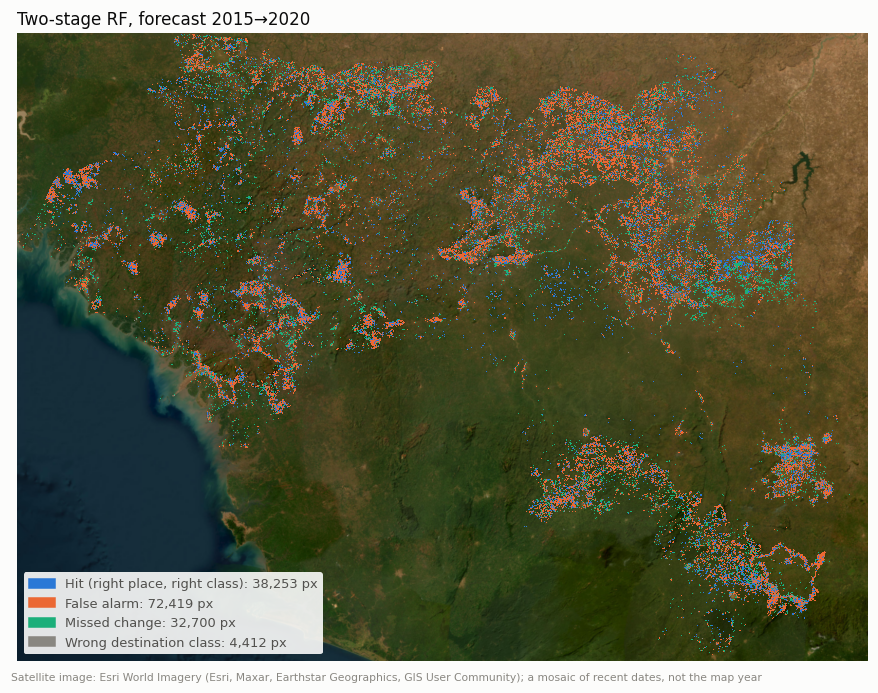

Precision of predicted change (right place and class): 33.2%  (intern: ~33.3%)   false alarms per hit: 1.89


In [11]:
pred = H.read_output_raster(f"{advanced.name}/final_two_stage_rf.tif")
emask = H.read_output_raster(f"{advanced.name}/evaluation_mask.tif").astype(bool)
codes = H.outcome_map(lc15, lc20, pred, emask)
H.plot_outcome_map(codes, "Two-stage RF, forecast 2015→2020", profile=H.read_map("Guinea_LandCover_2015.tif")[1])
plt.tight_layout(); plt.show()
hits, fa, wrong = (int((codes == k).sum()) for k in (2, 3, 5))
print(f"Precision of predicted change (right place and class): {100 * hits / (hits + fa + wrong):.1f}%  "
      f"(intern: ~33.3%)   false alarms per hit: {fa / hits:.2f}")

False alarms outnumber hits, which is the intern's central finding:
`FoM = hits / (observed change + false alarms)`, so with observed change fixed,
**every further point has to come from fewer false alarms**, not from finding more
change.

---

## 5 · Longer history, pooled periods

Assessing two previous intervals: whether a pixel returned to an older class, how long it has been stable, and transition densities in 7-, 21- and 51-pixel neighbourhoods. 
"Pooled" candidates also train on 2005→2010.

**Different protocol, so validation numbers are not comparable with section 4:**
fit 2010→2015 in training blocks and select on 2010→2015 *held-out blocks* (same
period, different place), which is easier. The forecast is still 2015→2020. The
RF control from this round (26.93%) is the baseline the satellite features in
notebook 03 are measured against.

In [12]:
memory = H.ensure_run("local_landuse.temporal_memory", "temporal_memory_20260909", [], RERUN["longer_history"])
tm = H.read_csv(memory / "final_comparison.csv")
report = json.loads((memory / "report.json").read_text())
val = {r["name"]: r["figure_of_merit_pct"] for r in report["validation"]}
m = lambda name: H.row(tm, "name", name, f)
memory_rows = H.compare([
    ("Same-protocol RF control", 26.93, m("recent_two_stage_rf_control"), 90.19,
     100 * H.row(tm, "name", "recent_two_stage_rf_control", a)),
    ("Pooled joint XGBoost (selected on validation)", 25.99, m("pooled_memory_joint_xgb"), None,
     100 * H.row(tm, "name", "pooled_memory_joint_xgb", a), H.TOL_XGB_THRESHOLD),
])
memory_rows.insert(1, "Validation FoM % (intern / ours)",
                   [f"30.40 / {val['recent_two_stage_rf_control']:.2f}",
                    f"31.53 / {val['pooled_memory_joint_xgb']:.2f}"])
print("Selected:", report["selected_model"])
H.show(memory_rows)

Using saved: outputs/temporal_memory_20260909
Selected: pooled_memory_joint_xgb


Configuration,"Validation FoM % (intern / Rerun (Python 3.10, xgboost 3.2))",Intern FoM %,"Rerun (Python 3.10, xgboost 3.2) FoM %",Δ FoM (pts),Intern accuracy %,"Rerun (Python 3.10, xgboost 3.2) accuracy %",Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
Same-protocol RF control,30.40 / 30.30,26.93,26.84,-0.09,90.19,90.35,0.40,yes
Pooled joint XGBoost (selected on validation),31.53 / 31.44,25.99,26.08,0.09,,90.35,0.85,yes


**Result: reproduces.** The same model is selected, and forecasts are within
0.1 point. As the intern found, the best validation score is *not* the best
forecast: longer history helps where the model was validated, but does not
carry over to the next period.

---

## Summary

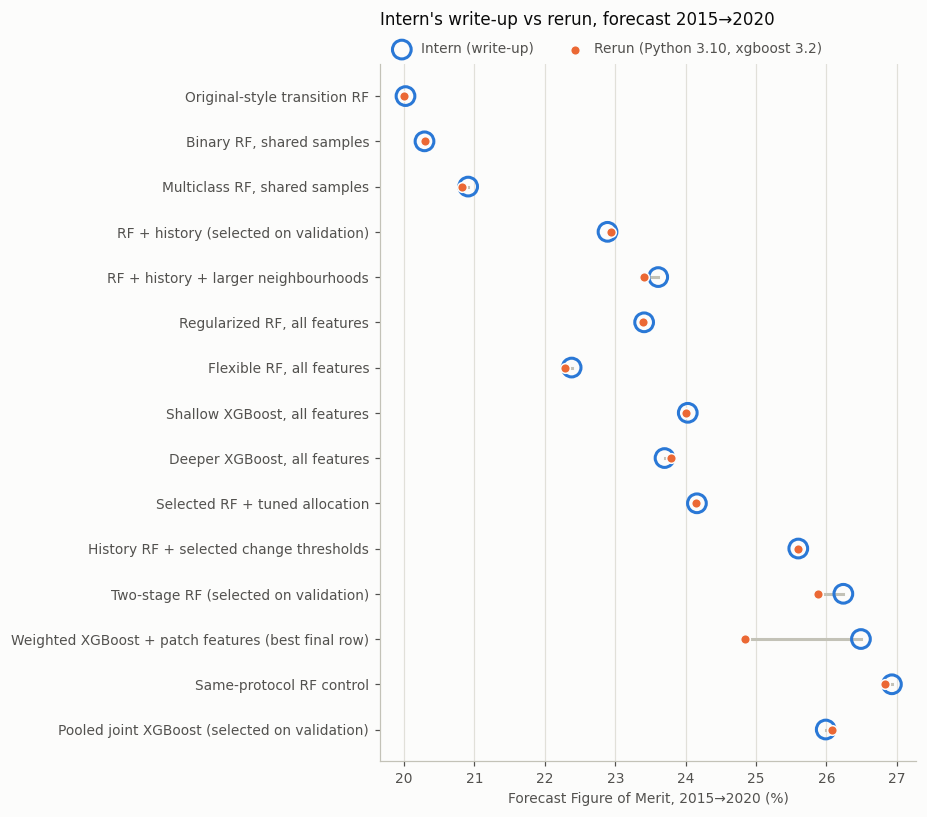

14 of 15 rows within their tolerance; largest gap among selected models: -0.36


In [13]:
everything = pd.concat([baselines.iloc[:3], history_rows.iloc[1:], advanced_rows.drop(columns=f"{H.RERUN_PY314} FoM %").iloc[[0, 1, 4]],
                        memory_rows.drop(columns=memory_rows.columns[1])], ignore_index=True)
H.plot_dumbbell(everything, "Intern's write-up vs rerun, forecast 2015→2020")
plt.tight_layout(); plt.show()
n_ok = (everything[H.REPRODUCES] == "yes").sum()
print(f"{n_ok} of {len(everything)} rows within their tolerance; "
      f"largest gap among selected models: {advanced_rows.iloc[1]['Δ FoM (pts)']:+.2f}")

| Step | Verdict |
|---|---|
| Inputs | Identical: 992,833 pixels, 75,365 observed changes |
| Original-style baselines | Reproduce (≤ 0.1 point) |
| History features | Reproduce. Same frozen selection. **+2 to +3 points, the main candidate to port to ESRI** |
| Change-focused models | The selected model reproduces (−0.36; −0.03 with the intern's package versions). One unselected row (26.49%) does not |
| Longer history | Reproduces. Validation gains do not carry over to the forecast, as reported |

In [14]:
# Keep the small summaries under outputs/summary/ (committed); full runs stay in the ignored outputs/ folder.
for frame, name in [(baselines, "01_baselines"), (history_rows, "01_history"),
                    (advanced_rows, "01_advanced"), (memory_rows, "01_longer_history")]:
    H.SUMMARY.mkdir(parents=True, exist_ok=True)
    H.relabel(frame).to_csv(H.SUMMARY / f"{name}.csv", index=False)
reversion.to_csv(H.SUMMARY / "01_label_reversion.csv", index=False)
print("Saved tables to", H.SUMMARY.relative_to(H.ROOT))

Saved tables to outputs\summary
